In [1]:
pip install librosa

/usr/local/lib/python3.13/dist-packages/librosa/core/spectrum.py:266: UserWarning: n_fft=2048 is too large for input signal of length=2023
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/librosa/core/spectrum.py:266: UserWarning: n_fft=2048 is too large for input signal of length=1843
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/librosa/core/spectrum.py:266: UserWarning: n_fft=2048 is too large for input signal of length=2015
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/librosa/core/spectrum.py:266: UserWarning: n_fft=2048 is too large for input signal of length=2020
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/librosa/core/spectrum.py:266: UserWarning: n_fft=2048 is too large for input signal of length=1976
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/librosa/core/spectrum.py:266: UserWarning: n_fft=2048 is too large for input signal of length=1932
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/librosa/core/spectrum.py

(3000, 32, 40) ['0' '1' '2' '3' '4' '5' '6' '7' '8' '9']
X shape: (3000, 32, 40)
y shape: (3000,)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_3 (LSTM)                   │ (None, 64)             │        26,880 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,290 (114.41 KB)

 Trainable params: 29,290 (114.41 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.2279 - loss: 2.1558 - val_accuracy: 0.4200 - val_loss: 1.7814
Epoch 2/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.6004 - loss: 1.2864 - val_accuracy: 0.7733 - val_loss: 0.8116
Epoch 3/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.8217 - loss: 0.6172 - val_accuracy: 0.8733 - val_loss: 0.4867
Epoch 4/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9033 - loss: 0.3583 - val_accuracy: 0.9000 - val_loss: 0.3214
Epoch 5/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9429 - loss: 0.2284 - val_accuracy: 0.9317 - val_loss: 0.2661
Epoch 6/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9638 - loss: 0.1527 - val_accuracy: 0.9417 - val_loss: 0.2091
Epoch 7/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9779 - loss: 0.1022 - val_accuracy: 0.9550 - val_loss: 0.1659
Epoch 8/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9750 - loss: 0.1074 - val_accuracy: 0.9467 - val_loss

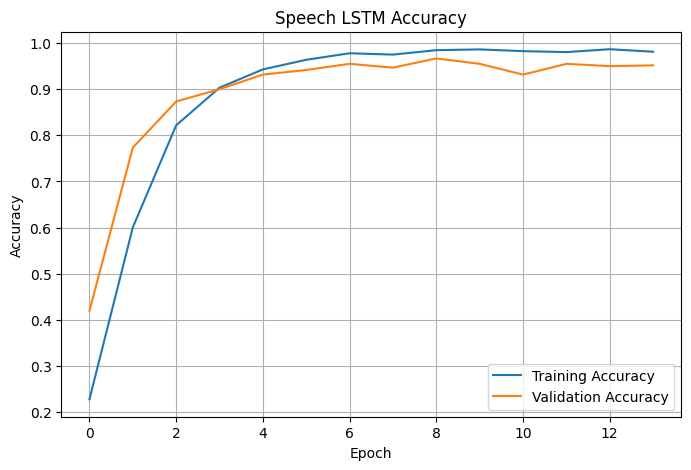

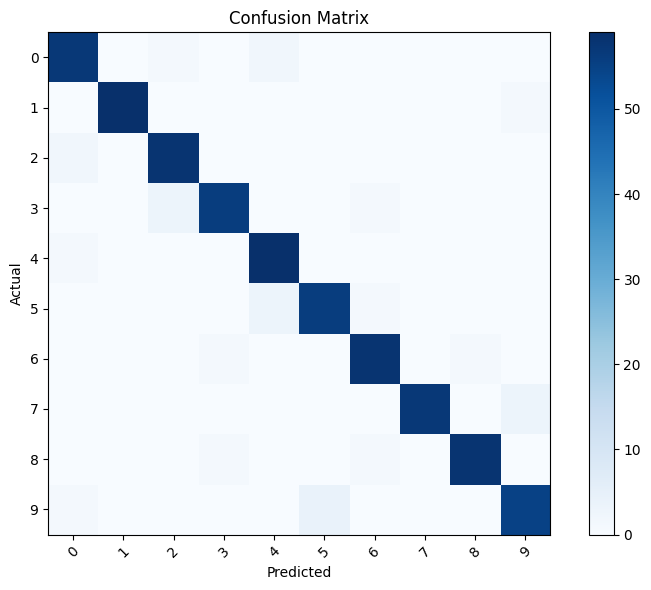

              precision    recall  f1-score   support

           0       0.93      0.95      0.94        60
           1       1.00      0.98      0.99        60
           2       0.94      0.97      0.95        60
           3       0.97      0.93      0.95        60
           4       0.92      0.98      0.95        60
           5       0.93      0.93      0.93        60
           6       0.95      0.97      0.96        60
           7       1.00      0.95      0.97        60
           8       0.98      0.97      0.97        60
           9       0.93      0.92      0.92        60

    accuracy                           0.95       600
   macro avg       0.96      0.95      0.96       600
weighted avg       0.96      0.95      0.96       600



In [5]:
import os
import zipfile
import random
import librosa
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping


random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)

import requests, zipfile, io, glob
url = "https://github.com/Jakobovski/free-spoken-digit-dataset/archive/refs/heads/master.zip"
zipfile.ZipFile(io.BytesIO(requests.get(url).content)).extractall("fsdd")

files = glob.glob("fsdd/*/recordings/*.wav")
max_len, n_mfcc = 32, 40
X_list, y_list = [], []
for f in files:
    audio, sr = librosa.load(f, sr=8000)
    mfcc = librosa.feature.mfcc(y=audio, sr=sr, n_mfcc=n_mfcc, hop_length=128).T
    mfcc = np.pad(mfcc, ((0, max(0, max_len - len(mfcc))), (0, 0)))[:max_len]
    X_list.append(mfcc.astype(np.float32))
    y_list.append(os.path.basename(f).split("_")[0])   # digit label from filename

X = np.array(X_list, dtype=np.float32)
y_raw = np.array(y_list)
print(X.shape, np.unique(y_raw))
y_raw = np.array(y_list)

print("X shape:", X.shape)
print("y shape:", y_raw.shape)

# 3. Encode labels and split
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_raw)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

# Normalize features using training-set mean/std per MFCC bin
mean = X_train.mean(axis=(0, 1), keepdims=True)
std = X_train.std(axis=(0, 1), keepdims=True) + 1e-8
X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

# 4. Build and train LSTM
speech_model = Sequential([
    LSTM(64, input_shape=(max_len, n_mfcc)),
    Dropout(0.3),
    Dense(32, activation="relu"),
    Dense(len(label_encoder.classes_), activation="softmax"),
])

speech_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
speech_model.summary()

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True,
)

history = speech_model.fit(
    X_train,
    y_train,
    validation_data=(X_test, y_test),
    epochs=20,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1,
)

test_loss, test_acc = speech_model.evaluate(X_test, y_test, verbose=0)
print(f"Test Loss: {test_loss:.4f} | Test Accuracy: {test_acc:.4f}")

# 5. Plot accuracy curve
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Speech LSTM Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# 6. Confusion matrix and classification report
y_pred = np.argmax(speech_model.predict(X_test, verbose=0), axis=1)

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
plt.imshow(cm, cmap="Blues")
plt.colorbar()
plt.xticks(range(len(label_encoder.classes_)), label_encoder.classes_, rotation=45)
plt.yticks(range(len(label_encoder.classes_)), label_encoder.classes_)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

print(classification_report(y_test, y_pred, target_names=label_encoder.classes_))